# Old script working for 2D data from https://analyticalscience.wiley.com/do/10.1002/was.0004000232

![image info](https://analyticalscience.wiley.com/cms/asset/010b306f-038d-429d-a22f-1422c69a6984/dantuon5_sim0122.png)

# Exercise A): fix the script, correcting the instruction to load images in napari

In [3]:
%gui qt
from skimage import io
import napari

myImage=io.imread('Documents/GitHub/MyFavoriteBIAtool_NEUBIAS_member/myImage.tif')
viewer = napari.view_image(myImage)

AttributeError: No napari attribute view_image

In [5]:
import numpy as np
from scipy import ndimage as ndi
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.filters import gaussian

gf_image=gaussian(myImage, sigma=1)
binary=gf_image>0.2
distance = ndi.distance_transform_edt(binary)
coords = peak_local_max(distance, footprint=np.ones((3, 3)), labels=binary)
mask = np.zeros(distance.shape, dtype=bool)
mask[tuple(coords.T)] = True
markers, _ = ndi.label(mask)
labels = watershed(-distance, markers, mask=binary)
viewer.add_image(labels, rgb=False, name='Labelled objects', opacity=0.6, colormap='inferno')

<Image layer 'Labelled objects' at 0x1ee5e30ee90>

# Exercise B):
# Load the built-in sample “Cells (3D - 2 Ch)” and try to segment the nuclei in 3D, 
# by adapting the 2D script from Fig. 5 of  https://analyticalscience.wiley.com/do/10.1002/was.0004000232

## Copy of the script above, which works for 2D images

In [ ]:
## Copy of the script working for 2D
%gui qt
from skimage import io
import napari

myImage=io.imread('Documents/GitHub/MyFavoriteBIAtool_NEUBIAS_member/myImage.tif')
viewer=napari.Viewer()
viewer.add_image(myImage)

In [ ]:
import numpy as np
from scipy import ndimage as ndi
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.filters import gaussian

gf_image=gaussian(myImage, sigma=1)
binary=gf_image>0.2
distance = ndi.distance_transform_edt(binary)
coords = peak_local_max(distance, footprint=np.ones((3, 3)), labels=binary)
mask = np.zeros(distance.shape, dtype=bool)
mask[tuple(coords.T)] = True
markers, _ = ndi.label(mask)
labels = watershed(-distance, markers, mask=binary)
viewer.add_image(labels, rgb=False, name='Labelled objects', opacity=0.6, colormap='inferno')

## Code to be fixed for getting 3D segmentation

In [34]:
import numpy as np
from scipy import ndimage as ndi
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.filters import gaussian


from skimage import data
from napari.utils import nbscreenshot

In [10]:
img=data.cells3d()

In [11]:
img.shape

(60, 2, 256, 256)

In [14]:
nuclei=img[:,1,:,:]

In [36]:
viewer.add_image(nuclei)

<Image layer 'nuclei [1]' at 0x1ee60826710>

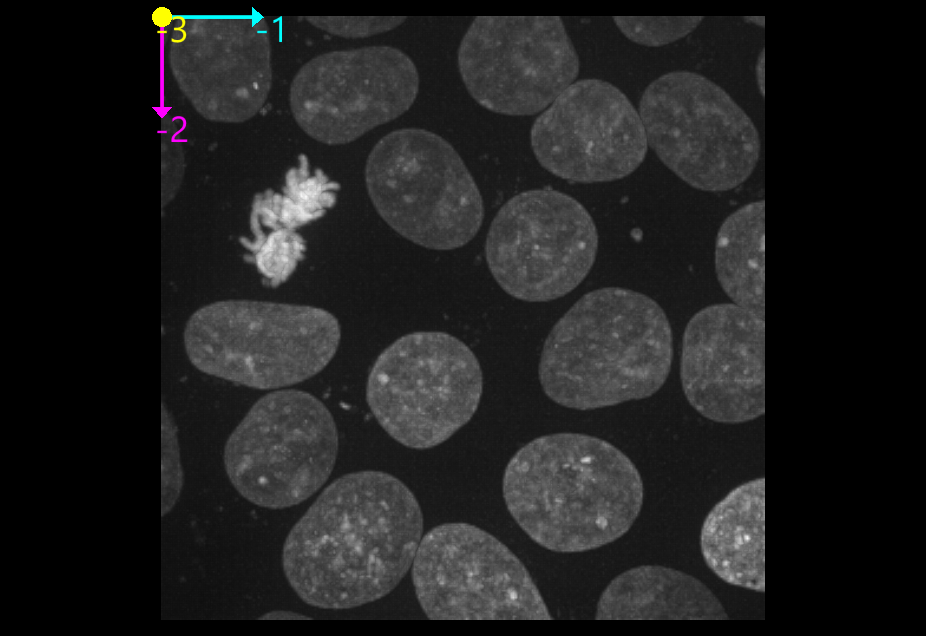

In [37]:
nbscreenshot(viewer, canvas_only=True)

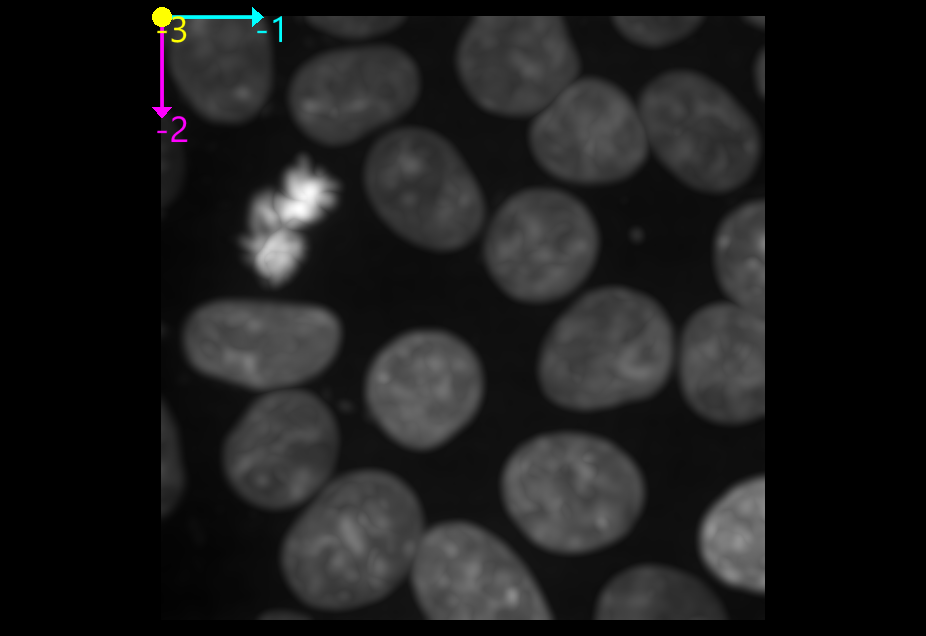

In [40]:
#Add Gaussian smoothed image to the viewer

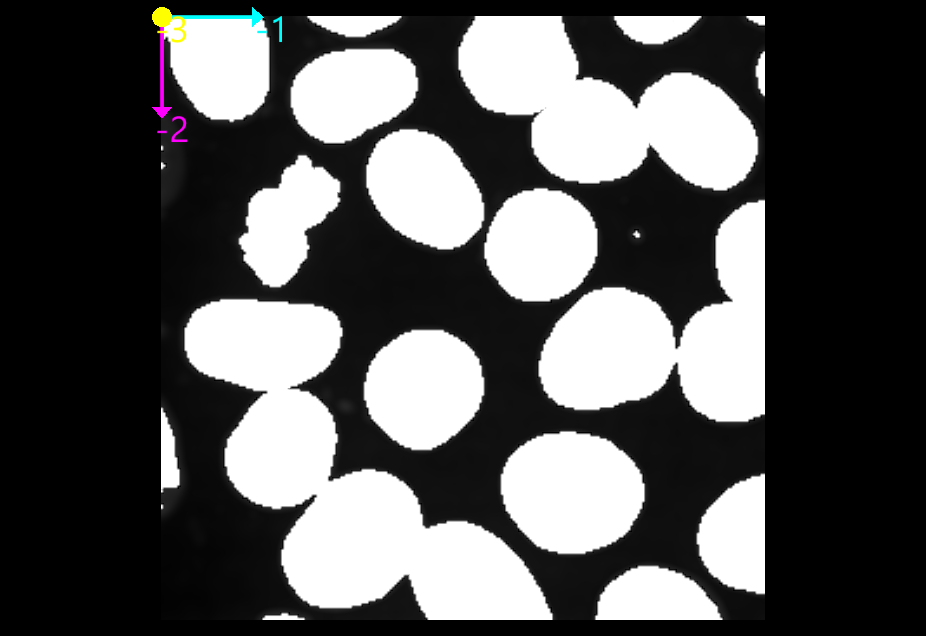

In [41]:
#Add binary image to the viewer

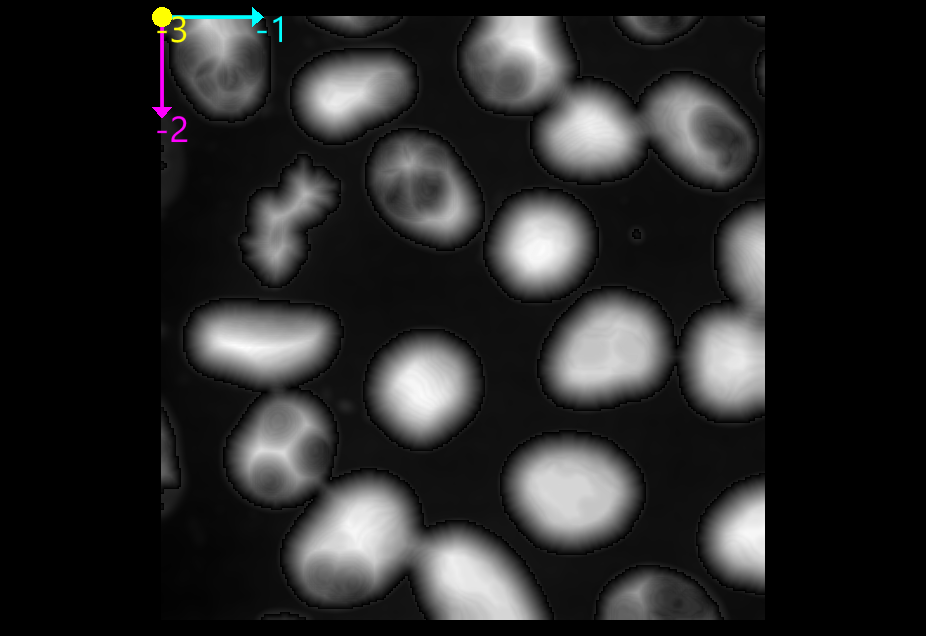

In [42]:
#Add distance map to the viewer

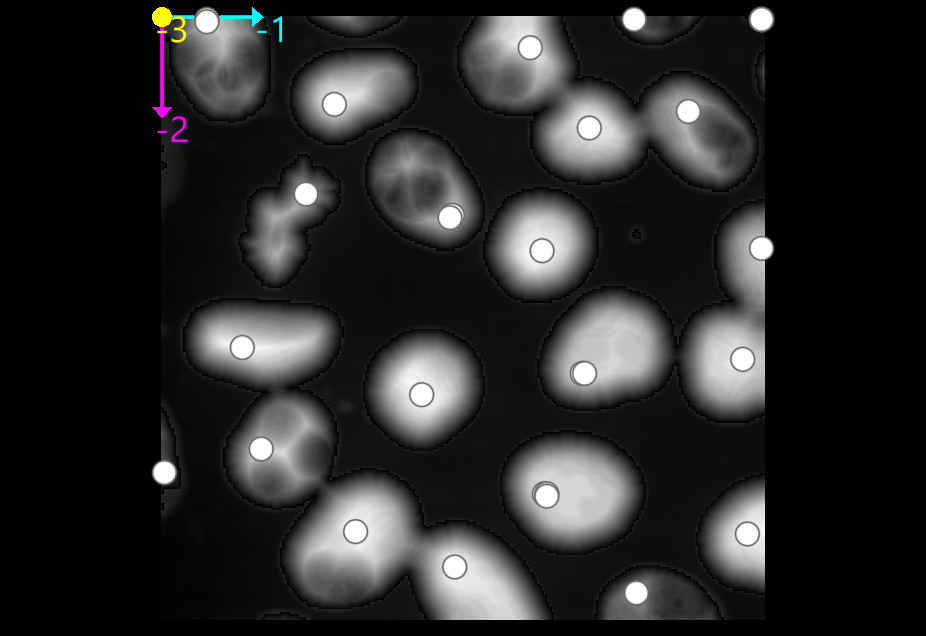

In [43]:
#Add local maxima points to the viewer

In [1]:
#Add labels image to the viewer

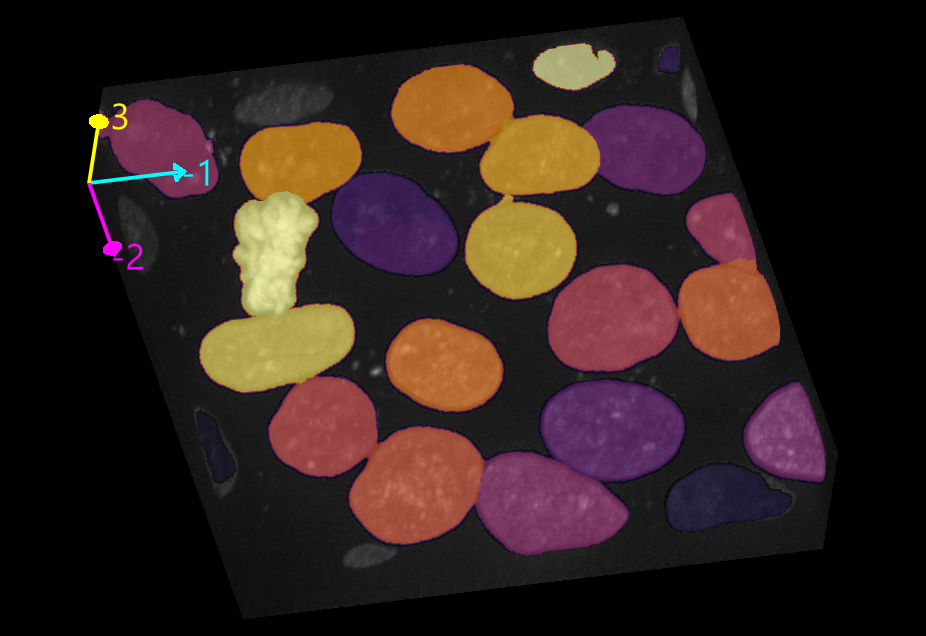

In [32]:
#Final segmentation
nbscreenshot(viewer, canvas_only=True)